# Retrieval of Historical Flood Inundation Data

This script is designed to retrieve historical flood inundation data for Busan, South Korea, from the Disaster and Safety Data Sharing Platform (재난안전데이터공유플랫폼). Using the platform's API and an authorized service key, it systematically acquires geospatial records delineating areas affected by historical flood events.

### Download data

In [ ]:
import requests
import pandas as pd
import time
import math
import os

# Setting
SERVICE_KEY = "EVY9G43W9532731L"
url = "https://www.safetydata.go.kr/V2/api/DSSP-IF-00117"
save_dir = r"C:\Users\nayou\OneDrive\문서\공모전\2026 부산 Big Data 활용대회\복기\침수흔적도"
os.makedirs(save_dir, exist_ok=True)


# Check total count with the initial API request before download
params = {
    "serviceKey": SERVICE_KEY,
    "returnType": "json",
    "pageNo": 1,
    "numOfRows": 1000
}

r = requests.get(url, params=params, timeout=60)
r.raise_for_status() # Check http error
data = r.json()
print(data.keys())

print("API condition:", data["header"])
print("totalCount:", data["totalCount"])

total_count = data["totalCount"]
num_rows = 1000
total_pages = math.ceil(total_count / num_rows)

print("Number of total pages:", total_pages)

dict_keys(['header', 'numOfRows', 'pageNo', 'totalCount', 'body'])
API condition: {'resultMsg': 'NORMAL SERVICE', 'resultCode': '00', 'errorMsg': None}
totalCount: 38003
Number of total pages: 39


In [3]:
# 1. Collect all pages
all_rows = []
for page in range(1, total_pages + 1):

    params = {
        "serviceKey": SERVICE_KEY,
        "returnType": "json",
        "pageNo": page,
        "numOfRows": num_rows
    }

    try:
        r = requests.get(url, params=params, timeout=60)
        r.raise_for_status()
        js = r.json()

        # Check for API-level errors
        if js["header"]["resultCode"] != "00":
            print(f"API error on page {page}:", js["header"])
            break

        rows = js.get("body", [])

        all_rows.extend(rows)

        print(
            f"{page}/{total_pages} Complete "
            f"| Retrieved {len(rows)} records "
            f"| Cumulative total: {len(all_rows)} records"
        )

        # Save checkpoints
        checkpoint = pd.DataFrame(all_rows)

        checkpoint.to_csv(
            os.path.join(
                save_dir,
                "Flood_history_checkpoint.csv"
            ),
            index=False,
            encoding="utf-8-sig"
        )

        # Prevent excessive server requests
        time.sleep(0.3)

    except Exception as e:
        print(f"Error on page {page}:", e)
        break



# 2. Create the complete DataFrame
df = pd.DataFrame(all_rows)
print("\nComplete dataset:")
print(df.shape)
print(df.columns.tolist())


# 3. Filter records for Busan
busan = df[
    df["STDG_CTPV_CD"].astype(str).str.zfill(2) == "26"
].copy()

print("\nBusan dataset:")
print(busan.shape)

if len(busan) > 0:
    print(
        busan[
            [
                "SN",
                "FLDN_YR",
                "FLDN_GRD",
                "FLDN_DOWA",
                "FLDN_AREA",
                "FLDN_CS_DTL_NM",
                "STDG_SGG_CD"
            ]
        ].head()
    )


# 4. Save final datasets
# Nationwide dataset
df.to_csv(
    os.path.join(
        save_dir,
        "Flood_history_Korea_raw.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

# Busan dataset
busan.to_csv(
    os.path.join(
        save_dir,
        "Flood_history_Busan_raw.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# 5. Perform basic data verification
print("\n======================")
print("Data successfully saved")
print("======================")

print("Nationwide:", df.shape)
print("Busan:", busan.shape)

if len(busan) > 0:
    print(
        "Temporal coverage of flood records in Busan:",
        busan["FLDN_YR"].min(),
        "~",
        busan["FLDN_YR"].max()
    )

    print("\nAnnual distribution of flood records in Busan:")
    print(
        busan["FLDN_YR"]
        .value_counts()
        .sort_index()
    )

1/39 Complete | Retrieved 1000 records | Cumulative total: 1000 records
2/39 Complete | Retrieved 1000 records | Cumulative total: 2000 records
3/39 Complete | Retrieved 1000 records | Cumulative total: 3000 records
4/39 Complete | Retrieved 1000 records | Cumulative total: 4000 records
5/39 Complete | Retrieved 1000 records | Cumulative total: 5000 records
6/39 Complete | Retrieved 1000 records | Cumulative total: 6000 records
7/39 Complete | Retrieved 1000 records | Cumulative total: 7000 records
8/39 Complete | Retrieved 1000 records | Cumulative total: 8000 records
9/39 Complete | Retrieved 1000 records | Cumulative total: 9000 records
10/39 Complete | Retrieved 1000 records | Cumulative total: 10000 records
11/39 Complete | Retrieved 1000 records | Cumulative total: 11000 records
12/39 Complete | Retrieved 1000 records | Cumulative total: 12000 records
13/39 Complete | Retrieved 1000 records | Cumulative total: 13000 records
14/39 Complete | Retrieved 1000 records | Cumulative tot

### Inspect the downloaded dataset

In [8]:
import pandas as pd
import geopandas as gpd
from shapely import wkt
import os

save_dir = r"C:\Users\nayou\OneDrive\문서\공모전\2026 부산 Big Data 활용대회\복기\침수흔적도"
csv_path = os.path.join(save_dir, "Flood_history_Busan_raw.csv")


# 1. Load the CSV file
df = pd.read_csv(csv_path)
print("Original dataset:", df.shape)


# 2. WKT -> geometry
# WKT (Well-Known Text): A standard text representation of spatial geometries
df["geometry"] = df["GEOM"].apply(wkt.loads)

# 3. Create a GeoDataFrame for geospatial analysis
# Geodataframe: A pandas Dataframe with geometry and spatial analysis capabilities
gdf = gpd.GeoDataFrame(df, geometry="geometry")
print(gdf.head())
print("Current CRS:", gdf.crs)
print("Bounds:")
print(gdf.total_bounds)

# Check the bounds
print(df["GEOM"].iloc[0])

Original dataset: (479, 14)
   FLDN_GRD  FLDN_DOWA  FLDN_END_YMD  FLDN_YR       FLDN_CS_DTL_NM  \
0         1      0.354      20140825     2014  집중호우로 인한 급격한 우수량 증가   
1         1      0.423      20140825     2014   집중호우로 인한 급격한 우수량증가   
2         2      0.594      20140825     2014   집중호우로 인한 급격한 우수량증가   
3         2      0.824      20140825     2014    집중호우로 우수량의 급격한 증가   
4         3      1.125      20140825     2014  집중호우로 인한 급격한 우수량 증가   

   FLDN_BGNG_YMD  STDG_SGG_CD  FLDN_END_TM   FLDN_AREA  STDG_CTPV_CD  \
0       20140825        26320         1600   46074.572            26   
1       20140825        26320         1600  153678.417            26   
2       20140825        26320         1600  153678.417            26   
3       20140825        26320         1600   20367.322            26   
4       20140825        26320         1600   18408.972            26   

  FLDN_DST_NM  SN                                               GEOM  \
0  2014년 집중호우  55  POLYGON((14361849.435000001

### Reproject Flood Inundation Data to EPSG:5179 and Save as GeoPackage

In [9]:
# The source CRS is assumed to be EPSG:3857 (Web Mercator),
# based on the coordinate ranges of the original WKT geometries.
# The bounding coordinates (X: 14.34–14.39 million,
# Y: 4.17–4.21 million) correspond to the Busan region
# when interpreted in EPSG:3857.
gdf = gdf.set_crs(epsg=3857)

# Reproject to EPSG:5179 (Korea 2000 / Unified CS)
# to ensure spatial consistency with other geospatial datasets.
gdf_5179 = gdf.to_crs(epsg=5179)

print("Reprojected CRS:", gdf_5179.crs)
print("5179 Bounds:")
print(gdf_5179.total_bounds)


# Save 
gpkg_path = os.path.join(
    save_dir,
    "Flood_history_Busan_5179.gpkg"
)

gdf_5179.to_file(
    gpkg_path,
    layer="flood_history_busan",
    driver="GPKG"
)

print("Saved:", gpkg_path)
print("CRS:", gdf_5179.crs)
print("Number of features:", len(gdf_5179))

Reprojected CRS: EPSG:5179
5179 Bounds:
[1119538.55230129 1670498.13090162 1162574.09410177 1709823.00470117]
Saved: C:\Users\nayou\OneDrive\문서\공모전\2026 부산 Big Data 활용대회\복기\침수흔적도\Flood_history_Busan_5179.gpkg
CRS: EPSG:5179
Number of features: 479


### Generate 25 m × 25 m Grids and Evaluate Flood Overlap Thresholds

Flood polygon union completed
Total number of generated grid cells: 2710428

Overlap ratio summary:
count    2.694000e+04
mean     7.520569e-01
std      3.533828e-01
min      2.100130e-08
25%      4.876460e-01
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: overlap_ratio, dtype: float64

Number of positive grid cells by threshold
>= 1%: 26,134 cells (97.0%)
>= 5%: 25,110 cells (93.2%)
>= 10%: 24,309 cells (90.2%)
>= 20%: 23,111 cells (85.8%)
>= 25%: 22,571 cells (83.8%)
>= 30%: 22,042 cells (81.8%)
>= 50%: 20,084 cells (74.6%)
>= 75%: 17,834 cells (66.2%)
>= 90%: 16,524 cells (61.3%)


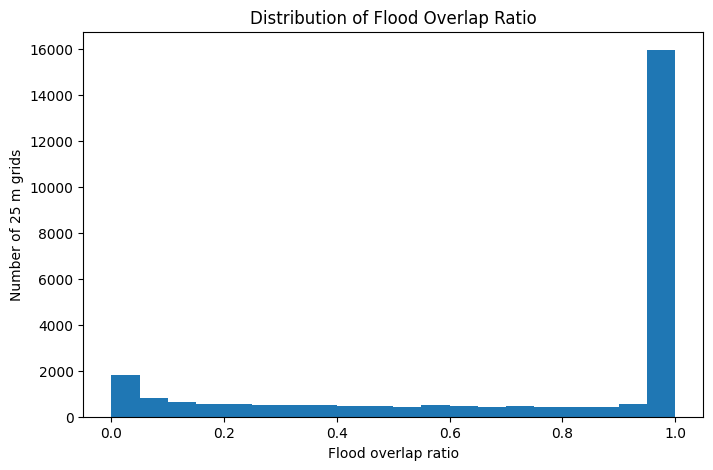

In [10]:
import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import box
import matplotlib.pyplot as plt

# 1. Merge all flood polygons into a single geometry
# Merge overlapping polygons from different years or flood events
# to avoid double-counting overlapping areas.
# Example: 100 m² (2020) + 50 m² (2021) - 10 m² (overlap) = 140 m²
flood_union = gdf_5179.geometry.union_all()
print("Flood polygon union completed")


# 2. Generate a 25 m grid around the flood-affected areas
grid_size = 25

minx, miny, maxx, maxy = flood_union.bounds # The bounding box is the smallest axis-aligned rectangle containing the entire flood-affected area.

# Align the bounding coordinates to the 25 m grid
minx = np.floor(minx / grid_size) * grid_size 
miny = np.floor(miny / grid_size) * grid_size
maxx = np.ceil(maxx / grid_size) * grid_size
maxy = np.ceil(maxy / grid_size) * grid_size

cells = []

for x in np.arange(minx, maxx, grid_size):
    for y in np.arange(miny, maxy, grid_size):
        cells.append(
            box(
                x,
                y,
                x + grid_size,
                y + grid_size
            )
        )

grid = gpd.GeoDataFrame(
    geometry=cells,
    crs="EPSG:5179"
)

print("Total number of generated grid cells:", len(grid))


# 3. Select grid cells that overlap or touch the flood polygons
# intersects() returns True if two geometries share any point, including boundary-only contact.
touching = grid[
    grid.geometry.intersects(flood_union)
].copy()



# 4. Calculate the overlap area
touching["overlap_area"] = touching.geometry.apply(
    lambda geom: geom.intersection(flood_union).area
)

# 25 m × 25 m = 625 m²
touching["overlap_ratio"] = (
    touching["overlap_area"] /
    (grid_size ** 2)
)

print("\nOverlap ratio summary:")
print(touching["overlap_ratio"].describe())


# 5. Count positive grid cells at different thresholds
thresholds = [
    0.01,
    0.05,
    0.10,
    0.20,
    0.25,
    0.30,
    0.50,
    0.75,
    0.90
]

print("\nNumber of positive grid cells by threshold")

for t in thresholds:
    n = (touching["overlap_ratio"] >= t).sum()
    print(
        f">= {t:.0%}: "
        f"{n:,} cells "
        f"({n / len(touching) * 100:.1f}%)"
    )



# 6. Histogram
plt.figure(figsize=(8, 5))

plt.hist(
    touching["overlap_ratio"],
    bins=20
)

plt.xlabel("Flood overlap ratio")
plt.ylabel("Number of 25 m grids")
plt.title("Distribution of Flood Overlap Ratio")

plt.show()
